# Do Neighboring Regions' Alert Status Improve Predictions?
> **Companion to notebooks 01-02.** PLAN.md (Section 4.1) calls spatial
> context - whether neighboring oblasts are also under alert - "likely the
> most valuable feature group," but it was deferred in the first pass. The
> currently-served model (`AlertPredictionPipeline`, trained in `train.py`)
> only uses `[region_id, elapsed_min, hour_sin/cos, dow_sin/cos, is_weekend,
> month]` - each region is predicted independently, with no awareness of
> what's happening next door.
>
> This notebook tests the hypothesis directly: train the **same model**,
> **same recency-weighting**, **same train/test split** as `train.py`, with
> and without point-in-time neighbor features, and compare on held-out data.
>
> *Disclaimer: statistical experiment for research and analysis. Decides
> nothing about the app by itself - see the verdict cell at the end.*


## 1. Setup & Imports


In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root / "src"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from alertpred.config import OBLAST_NEIGHBORS, RECENCY_HALF_LIFE_DAYS
from alertpred.data.build_dataset import build_master_alerts_dataset
from alertpred.data.cleaning import create_time_split
from alertpred.features.builder import (
    sample_as_of_alert_moments,
    sample_as_of_gap_moments,
    compute_recency_weight,
    compute_neighbor_active_features,
)
from alertpred.models.quantile_lgbm import LightGBMQuantileModel, LightGBMProbabilityModel
from alertpred.evaluation.metrics import evaluate_quantile_predictions, evaluate_classification_probabilities

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

print(f"Project root: {project_root}")


Project root: /Users/allakovalcuk/Agentic_AI


## 2. Load the Master Dataset
Same pipeline as `train.py` / notebook 01: bias-corrected oblast rollup +
alerts.in.ua backfill + volunteer gap-fill.


In [2]:
df_alerts, df_gaps = build_master_alerts_dataset(use_api_backfill=True)
print(f"Alert episodes: {len(df_alerts):,}  |  Gap episodes: {len(df_gaps):,}")
print(f"Date range: {df_alerts['started_at'].min().strftime('%Y-%m-%d')} to {df_alerts['started_at'].max().strftime('%Y-%m-%d')}")


  [1/27] khmelnytskyi (uid=3): 106 completed episodes
  [2/27] vinnytsia (uid=4): 147 completed episodes


  [3/27] rivne (uid=5): 127 completed episodes
  [4/27] volyn (uid=8): 67 completed episodes


  [5/27] dnipropetrovsk (uid=9): 0 completed episodes (1 dropped, >72h merged chain)
  [6/27] zhytomyr (uid=10): 230 completed episodes
  [7/27] zakarpattia (uid=11): 3 completed episodes


  [8/27] zaporizhzhia (uid=12): 159 completed episodes
  [9/27] ivano_frankivsk (uid=13): 16 completed episodes


  [10/27] kyiv (uid=14): 238 completed episodes


...

  [18/27] kharkiv (uid=22): 225 completed episodes
  [19/27] kherson (uid=23): 258 completed episodes


  [20/27] cherkasy (uid=24): 228 completed episodes
  [21/27] chernihiv (uid=25): 187 completed episodes


  [22/27] chernivtsi (uid=26): 34 completed episodes
  [23/27] lviv (uid=27): 18 completed episodes
  [24/27] donetsk (uid=28): 69 completed episodes
  [25/27] crimea (uid=29): 0 completed episodes
  [26/27] sevastopol (uid=30): 0 completed episodes


  [27/27] kyiv_city (uid=31): 218 completed episodes


Filling 4 days 20:42:52.858000 gap (2026-09-07 to 2026-09-12) with 575 volunteer-sourced episodes
Alert episodes: 84,486  |  Gap episodes: 84,445
Date range: 2022-03-15 to 2026-10-12


## 3. Chronological Split, Recency Weights, As-Of Samples
Identical to `train.py`'s production methodology (same 80/20 chronological
split, same recency half-life) so this experiment isolates the effect of
adding neighbor features - not a different training recipe.


In [3]:
TRAIN_RATIO = 0.80

alerts_train, alerts_test = create_time_split(df_alerts, timestamp_col='started_at', train_ratio=TRAIN_RATIO)
gaps_train, gaps_test = create_time_split(df_gaps, timestamp_col='gap_start', train_ratio=TRAIN_RATIO)

reference_ts = df_alerts['started_at'].max()
alerts_train['recency_weight'] = compute_recency_weight(alerts_train['started_at'], reference_ts, RECENCY_HALF_LIFE_DAYS)
gaps_train['recency_weight'] = compute_recency_weight(gaps_train['gap_start'], reference_ts, RECENCY_HALF_LIFE_DAYS)

train_a = sample_as_of_alert_moments(alerts_train)
test_a = sample_as_of_alert_moments(alerts_test)
train_b = sample_as_of_gap_moments(gaps_train)
test_b = sample_as_of_gap_moments(gaps_test)

# Recency weight doesn't survive as-of sampling's row-by-row construction - join it back
train_a = train_a.merge(alerts_train[['region_id', 'started_at', 'recency_weight']].rename(columns={'started_at': 'start_ts'}), on=['region_id', 'start_ts'], how='left')
train_b = train_b.merge(gaps_train[['region_id', 'gap_start', 'recency_weight']].rename(columns={'gap_start': 'gap_start_ts'}), on=['region_id', 'gap_start_ts'], how='left')

print(f"Task A -> train: {len(train_a):,}, test: {len(test_a):,}")
print(f"Task B -> train: {len(train_b):,}, test: {len(test_b):,}")


Task A -> train: 460,727, test: 114,247
Task B -> train: 292,952, test: 49,947


## 4. Compute Point-in-Time Neighbor Features
`compute_neighbor_active_features` answers, for each historical (region,
as-of-moment) snapshot: how many of this region's direct neighbors (per
`config.OBLAST_NEIGHBORS`) - and how many regions nationally - had an
*active* episode at that exact moment. It's a backward as-of join against
each region's own sorted episode table, so only episodes that had already
started by that moment can match - no future information leaks in.

Computed separately for Task A (against `df_alerts`, "is my neighbor
currently mid-alert") and Task B (also against `df_alerts` - the question
during a *quiet* period is still "is a neighbor currently alerting," since
that's a plausible precursor signal for this region's own next alert).


In [4]:
train_a = compute_neighbor_active_features(train_a, df_alerts, OBLAST_NEIGHBORS)
test_a = compute_neighbor_active_features(test_a, df_alerts, OBLAST_NEIGHBORS)
train_b = compute_neighbor_active_features(train_b, df_alerts, OBLAST_NEIGHBORS)
test_b = compute_neighbor_active_features(test_b, df_alerts, OBLAST_NEIGHBORS)

print("Task A neighbor feature summary (test set):")
display(test_a[['neighbors_active_count', 'neighbors_active_frac', 'national_active_count']].describe().round(2))


Task A neighbor feature summary (test set):


,neighbors_active_count,neighbors_active_frac,national_active_count
count,114247.00,114247.00,114247.00
mean,1.83,0.44,7.99
std,1.27,0.27,4.13
min,0.00,0.00,1.00
25%,1.00,0.25,5.00
50%,2.00,0.40,7.00
75%,2.00,0.67,10.00
max,7.00,1.00,24.00


## 5. Task A: With vs. Without Neighbor Features
Two identical `LightGBMQuantileModel` + `LightGBMProbabilityModel` pairs,
both recency-weighted, differing only in `feature_cols`.


In [5]:
BASE_FEATURES_A = ['region_id', 'elapsed_min', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'month']
NEIGHBOR_FEATURES = ['neighbors_active_count', 'neighbors_active_frac', 'national_active_count']

results = []

for label, feature_cols in [('Without Neighbors (current)', BASE_FEATURES_A), ('With Neighbors', BASE_FEATURES_A + NEIGHBOR_FEATURES)]:
    quant = LightGBMQuantileModel(feature_cols=feature_cols)
    quant.fit(train_a, target_col='target_remaining_min', weight_col='recency_weight')
    pred = quant.predict(test_a)
    m = evaluate_quantile_predictions(test_a['target_remaining_min'].values, pred['pred_p10'].values, pred['pred_p50'].values, pred['pred_p90'].values)
    results.append({'task': 'A', 'variant': label, **m})

    if label == 'With Neighbors':
        importances = pd.Series(quant.models[0.5].feature_importances_, index=feature_cols).sort_values(ascending=False)

df_res_a = pd.DataFrame(results).set_index(['task', 'variant'])
display(df_res_a.round(2))


mae_p50_min  median_ae_p50_min  \
task variant                                                       
A    Without Neighbors (current)       108.49              45.48   
     With Neighbors                    108.32              46.09   

                                  pinball_loss_p10  pinball_loss_p50  \
task variant                                                           
A    Without Neighbors (current)             12.98             54.24   
     With Neighbors                          12.99             54.16   

                                  pinball_loss_p90  mean_pinball_loss  \
task variant                                                            
A    Without Neighbors (current)             47.34              38.19   
     With Neighbors                          46.71              37.95   

                                  coverage_p10_p90  
task variant                                        
A    Without Neighbors (current)              0.75  
     With Neighbors                           0.75

LightGBM P50 feature importances, Task A, with neighbor features included:


hour_sin                  792
hour_cos                  733
month                     694
national_active_count     555
region_id                 408
elapsed_min               361
dow_sin                   358
neighbors_active_frac     231
dow_cos                   215
neighbors_active_count    126
is_weekend                 27
dtype: int32

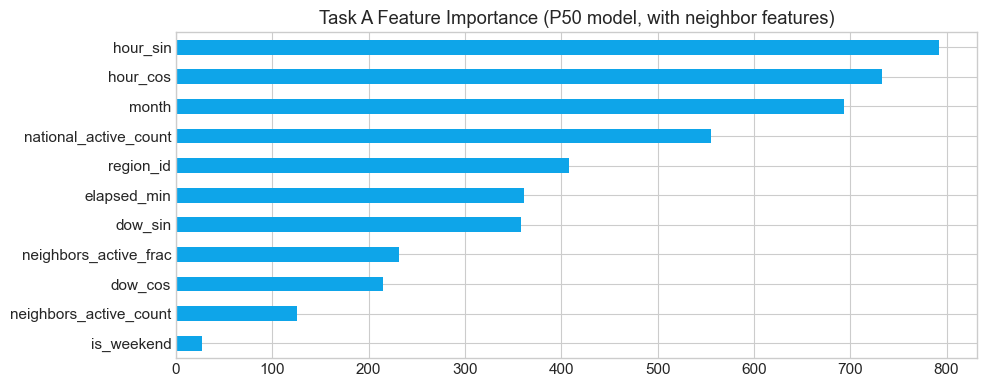

In [6]:
print("LightGBM P50 feature importances, Task A, with neighbor features included:")
display(importances)

plt.figure(figsize=(10, 4))
importances.sort_values().plot(kind='barh', color='#0ea5e9')
plt.title("Task A Feature Importance (P50 model, with neighbor features)")
plt.tight_layout()
plt.show()


## 6. Task B: With vs. Without Neighbor Features
Same comparison for time-to-next-alert.


In [7]:
BASE_FEATURES_B = ['region_id', 'elapsed_quiet_min', 'prev_alert_duration_min', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'month']

for label, feature_cols in [('Without Neighbors (current)', BASE_FEATURES_B), ('With Neighbors', BASE_FEATURES_B + NEIGHBOR_FEATURES)]:
    quant = LightGBMQuantileModel(feature_cols=feature_cols)
    quant.fit(train_b, target_col='target_remaining_gap_min', weight_col='recency_weight')
    pred = quant.predict(test_b)
    m = evaluate_quantile_predictions(test_b['target_remaining_gap_min'].values, pred['pred_p10'].values, pred['pred_p50'].values, pred['pred_p90'].values)
    results.append({'task': 'B', 'variant': label, **m})

    if label == 'With Neighbors':
        importances_b = pd.Series(quant.models[0.5].feature_importances_, index=feature_cols).sort_values(ascending=False)

df_res_b = pd.DataFrame([r for r in results if r['task'] == 'B']).set_index(['task', 'variant'])
display(df_res_b.round(2))
print("\nFeature importances, Task B, with neighbor features included:")
display(importances_b)


mae_p50_min  median_ae_p50_min  \
task variant                                                       
B    Without Neighbors (current)       609.79             205.91   
     With Neighbors                    591.88             178.65   

                                  pinball_loss_p10  pinball_loss_p50  \
task variant                                                           
B    Without Neighbors (current)             64.86            304.89   
     With Neighbors                          63.87            295.94   

                                  pinball_loss_p90  mean_pinball_loss  \
task variant                                                            
B    Without Neighbors (current)            271.86             213.87   
     With Neighbors                         276.28             212.03   

                                  coverage_p10_p90  
task variant                                        
B    Without Neighbors (current)              0.72  
     With Neighbors                           0.73


Feature importances, Task B, with neighbor features included:


prev_alert_duration_min    1247
month                       577
hour_cos                    531
hour_sin                    502
dow_sin                     340
region_id                   338
national_active_count       316
elapsed_quiet_min           286
dow_cos                     187
neighbors_active_frac       117
neighbors_active_count       37
is_weekend                   22
dtype: int32

## 7. Probability Models: Does "Ends/Starts Within Xh" Calibration Improve?
The quantile regressors answer "how long," but the app also shows threshold
probabilities ("ends within 30 min: 41%"). Check those separately since a
model can win on MAE but not on calibrated probabilities, or vice versa.


In [8]:
from alertpred.config import TASK_A_HORIZONS_MIN

prob_results = []
for label, feature_cols in [('Without Neighbors (current)', BASE_FEATURES_A), ('With Neighbors', BASE_FEATURES_A + NEIGHBOR_FEATURES)]:
    probs = LightGBMProbabilityModel(target_horizons=TASK_A_HORIZONS_MIN, horizon_prefix='ends_within_', horizon_suffix='m', feature_cols=feature_cols)
    probs.fit(train_a, weight_col='recency_weight')
    pred_proba = probs.predict_proba(test_a)
    for h in TASK_A_HORIZONS_MIN:
        target_col = f'target_ends_within_{h}m'
        prob_col = f'prob_ends_within_{h}m'
        m = evaluate_classification_probabilities(test_a[target_col].values, pred_proba[prob_col].values)
        prob_results.append({'variant': label, 'horizon_min': h, **m})

df_prob = pd.DataFrame(prob_results).set_index(['horizon_min', 'variant'])
display(df_prob.round(4))


,,brier_score,accuracy,roc_auc,log_loss
horizon_min,variant,,,,
15,Without Neighbors (current),0.1518,0.8004,0.6392,0.4778
30,Without Neighbors (current),0.2213,0.6488,0.6450,0.6332
60,Without Neighbors (current),0.2295,0.6209,0.6691,0.6525
15,With Neighbors,0.1521,0.7990,0.6383,0.4786
30,With Neighbors,0.2220,0.6515,0.6462,0.6360
60,With Neighbors,0.2327,0.6214,0.6626,0.6654


## 8. Verdict
Compares MAE and pinball loss (lower is better for both) across every
(task, variant) pair, plus where neighbor features ranked in importance.
A real recommendation, not a decision already made - the next step if this
looks worthwhile is wiring `compute_neighbor_active_features` into
`train.py` the same way recency-weighting was wired in.


In [9]:
summary = pd.DataFrame(results)
pivot = summary.pivot(index='task', columns='variant', values=['mae_p50_min', 'mean_pinball_loss', 'coverage_p10_p90'])
display(pivot.round(2))

for task in ['A', 'B']:
    base = summary[(summary['task'] == task) & (summary['variant'].str.contains('Without'))].iloc[0]
    neigh = summary[(summary['task'] == task) & (summary['variant'].str.contains('With Neighbors'))].iloc[0]
    mae_delta_pct = 100 * (neigh['mae_p50_min'] - base['mae_p50_min']) / base['mae_p50_min']
    pinball_delta_pct = 100 * (neigh['mean_pinball_loss'] - base['mean_pinball_loss']) / base['mean_pinball_loss']
    direction = "improves" if mae_delta_pct < 0 else "worsens"
    print(f"Task {task}: adding neighbor features {direction} MAE by {abs(mae_delta_pct):.1f}% "
          f"({'improves' if pinball_delta_pct < 0 else 'worsens'} pinball loss by {abs(pinball_delta_pct):.1f}%)")

print(f"\nTask A neighbor-feature importance rank (of {len(BASE_FEATURES_A) + len(NEIGHBOR_FEATURES)} features): "
      f"{[f for f in importances.index if f in NEIGHBOR_FEATURES]}")
print("(top of the list = most used by the model; compare position against elapsed_min/region_id)")


mae_p50_min                             mean_pinball_loss  \
variant With Neighbors Without Neighbors (current)    With Neighbors   
task                                                                   
A               108.32                      108.49             37.95   
B               591.88                      609.79            212.03   

                                    coverage_p10_p90  \
variant Without Neighbors (current)   With Neighbors   
task                                                   
A                             38.19             0.75   
B                            213.87             0.73   

                                     
variant Without Neighbors (current)  
task                                 
A                              0.75  
B                              0.72

Task A: adding neighbor features improves MAE by 0.2% (improves pinball loss by 0.6%)
Task B: adding neighbor features improves MAE by 2.9% (improves pinball loss by 0.9%)

Task A neighbor-feature importance rank (of 11 features): ['national_active_count', 'neighbors_active_frac', 'neighbors_active_count']
(top of the list = most used by the model; compare position against elapsed_min/region_id)
